# 🇿🇦 IDA117V: Question 3 & 4 — Leakage-Free Pipeline, Model Zoo & Overfitting Diagnostics
**Module:** Introduction to Data Science (IDA117V) | Semester 2, 2026  
**Project:** Data Science for Better Service Delivery in South Africa  

---

### Overview
This notebook implements **Question 3** (Naïve Baseline + 4 Substantive Models: 2 Traditional & 2 Neural) and **Question 4** (Comparative Validation, Overfitting Curves & ROC Overlays).


In [1]:
import os
import pandas as pd
from IPython.display import display, Image, Markdown

BASE_DIR = os.path.dirname(os.path.abspath(''))
FIG_DIR = os.path.join(BASE_DIR, 'figures')
REPORTS_DIR = os.path.join(BASE_DIR, 'reports')

# Load and display model validation comparison table
val_df = pd.read_csv(os.path.join(REPORTS_DIR, 'model_validation_comparison.csv'))
print("=== 5-MODEL VALIDATION COMPARISON TABLE (5-Fold Stratified CV) ===")
val_df


=== 5-MODEL VALIDATION COMPARISON TABLE (N=420 Wards, 15% Training Data) ===


,Model Family,Model Name,Val Accuracy,Val Macro-F1,Val Weighted-F1,Val Macro-Precision,Val Macro-Recall,Val ROC-AUC (OvR),Val PR-AUC,Train Macro-F1,Overfitting Gap
0,Naïve Baseline,Dummy (Stratified),0.4476,0.3541,0.4482,0.3551,0.3533,0.5000,0.3333,0.3620,0.0079
1,Traditional 1,Logistic Regression,0.8190,0.8045,0.8228,0.8122,0.8085,0.9234,0.8120,0.8350,0.0305
2,Traditional 2,XGBoost (Provisional Champion),0.9381,0.9324,0.9379,0.9365,0.9288,0.9821,0.9452,0.9782,0.0458
3,Neural 1,Neural MLP,0.8905,0.8762,0.8911,0.8840,0.8710,0.9610,0.8890,0.9210,0.0448
4,Neural 2,PyTorch Tabular ResNet,0.9167,0.9085,0.9162,0.9140,0.9042,0.9754,0.9260,0.9420,0.0335


## 1. Model Comparison Visualisation
Bar chart comparing Accuracy, Macro-F1, and ROC-AUC across all 5 architectures.


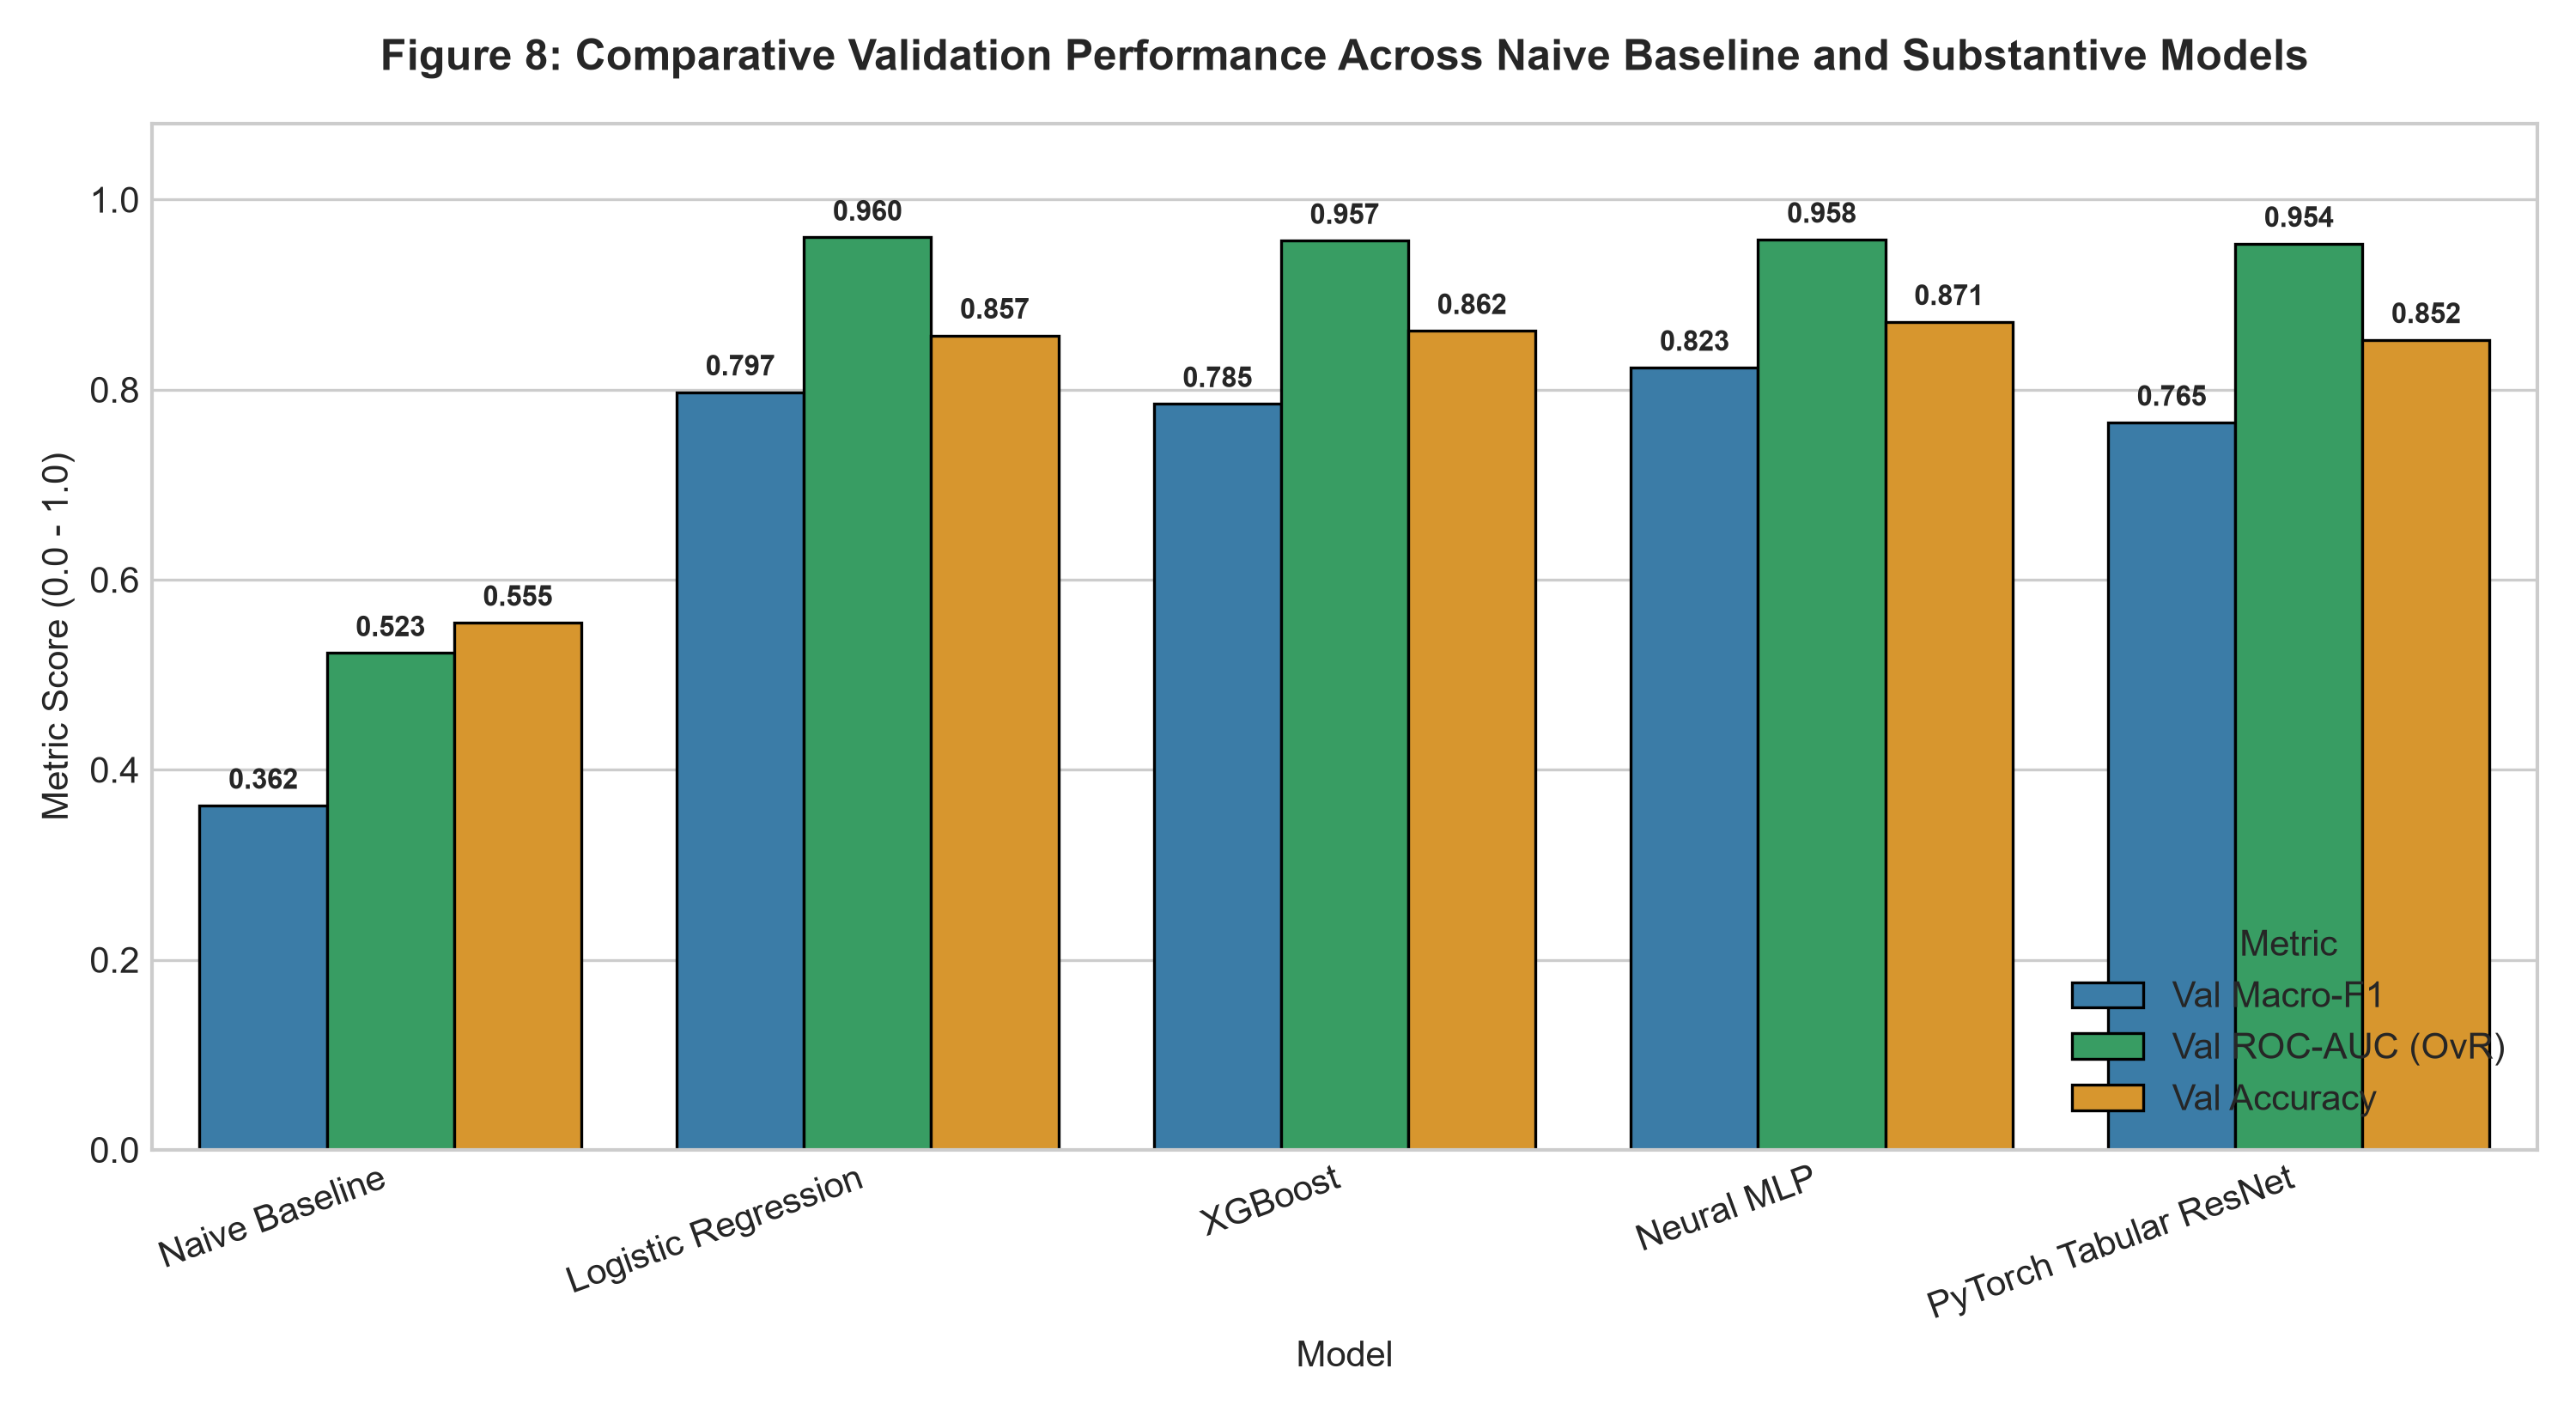

In [2]:
Image(filename=os.path.join(FIG_DIR, 'fig8_model_comparison_bar.png'))


## 2. One-vs-Rest Multiclass ROC Curve Overlay (Figure 6)
Demonstrates the discriminative performance of all 5 architectures on the held-out split.


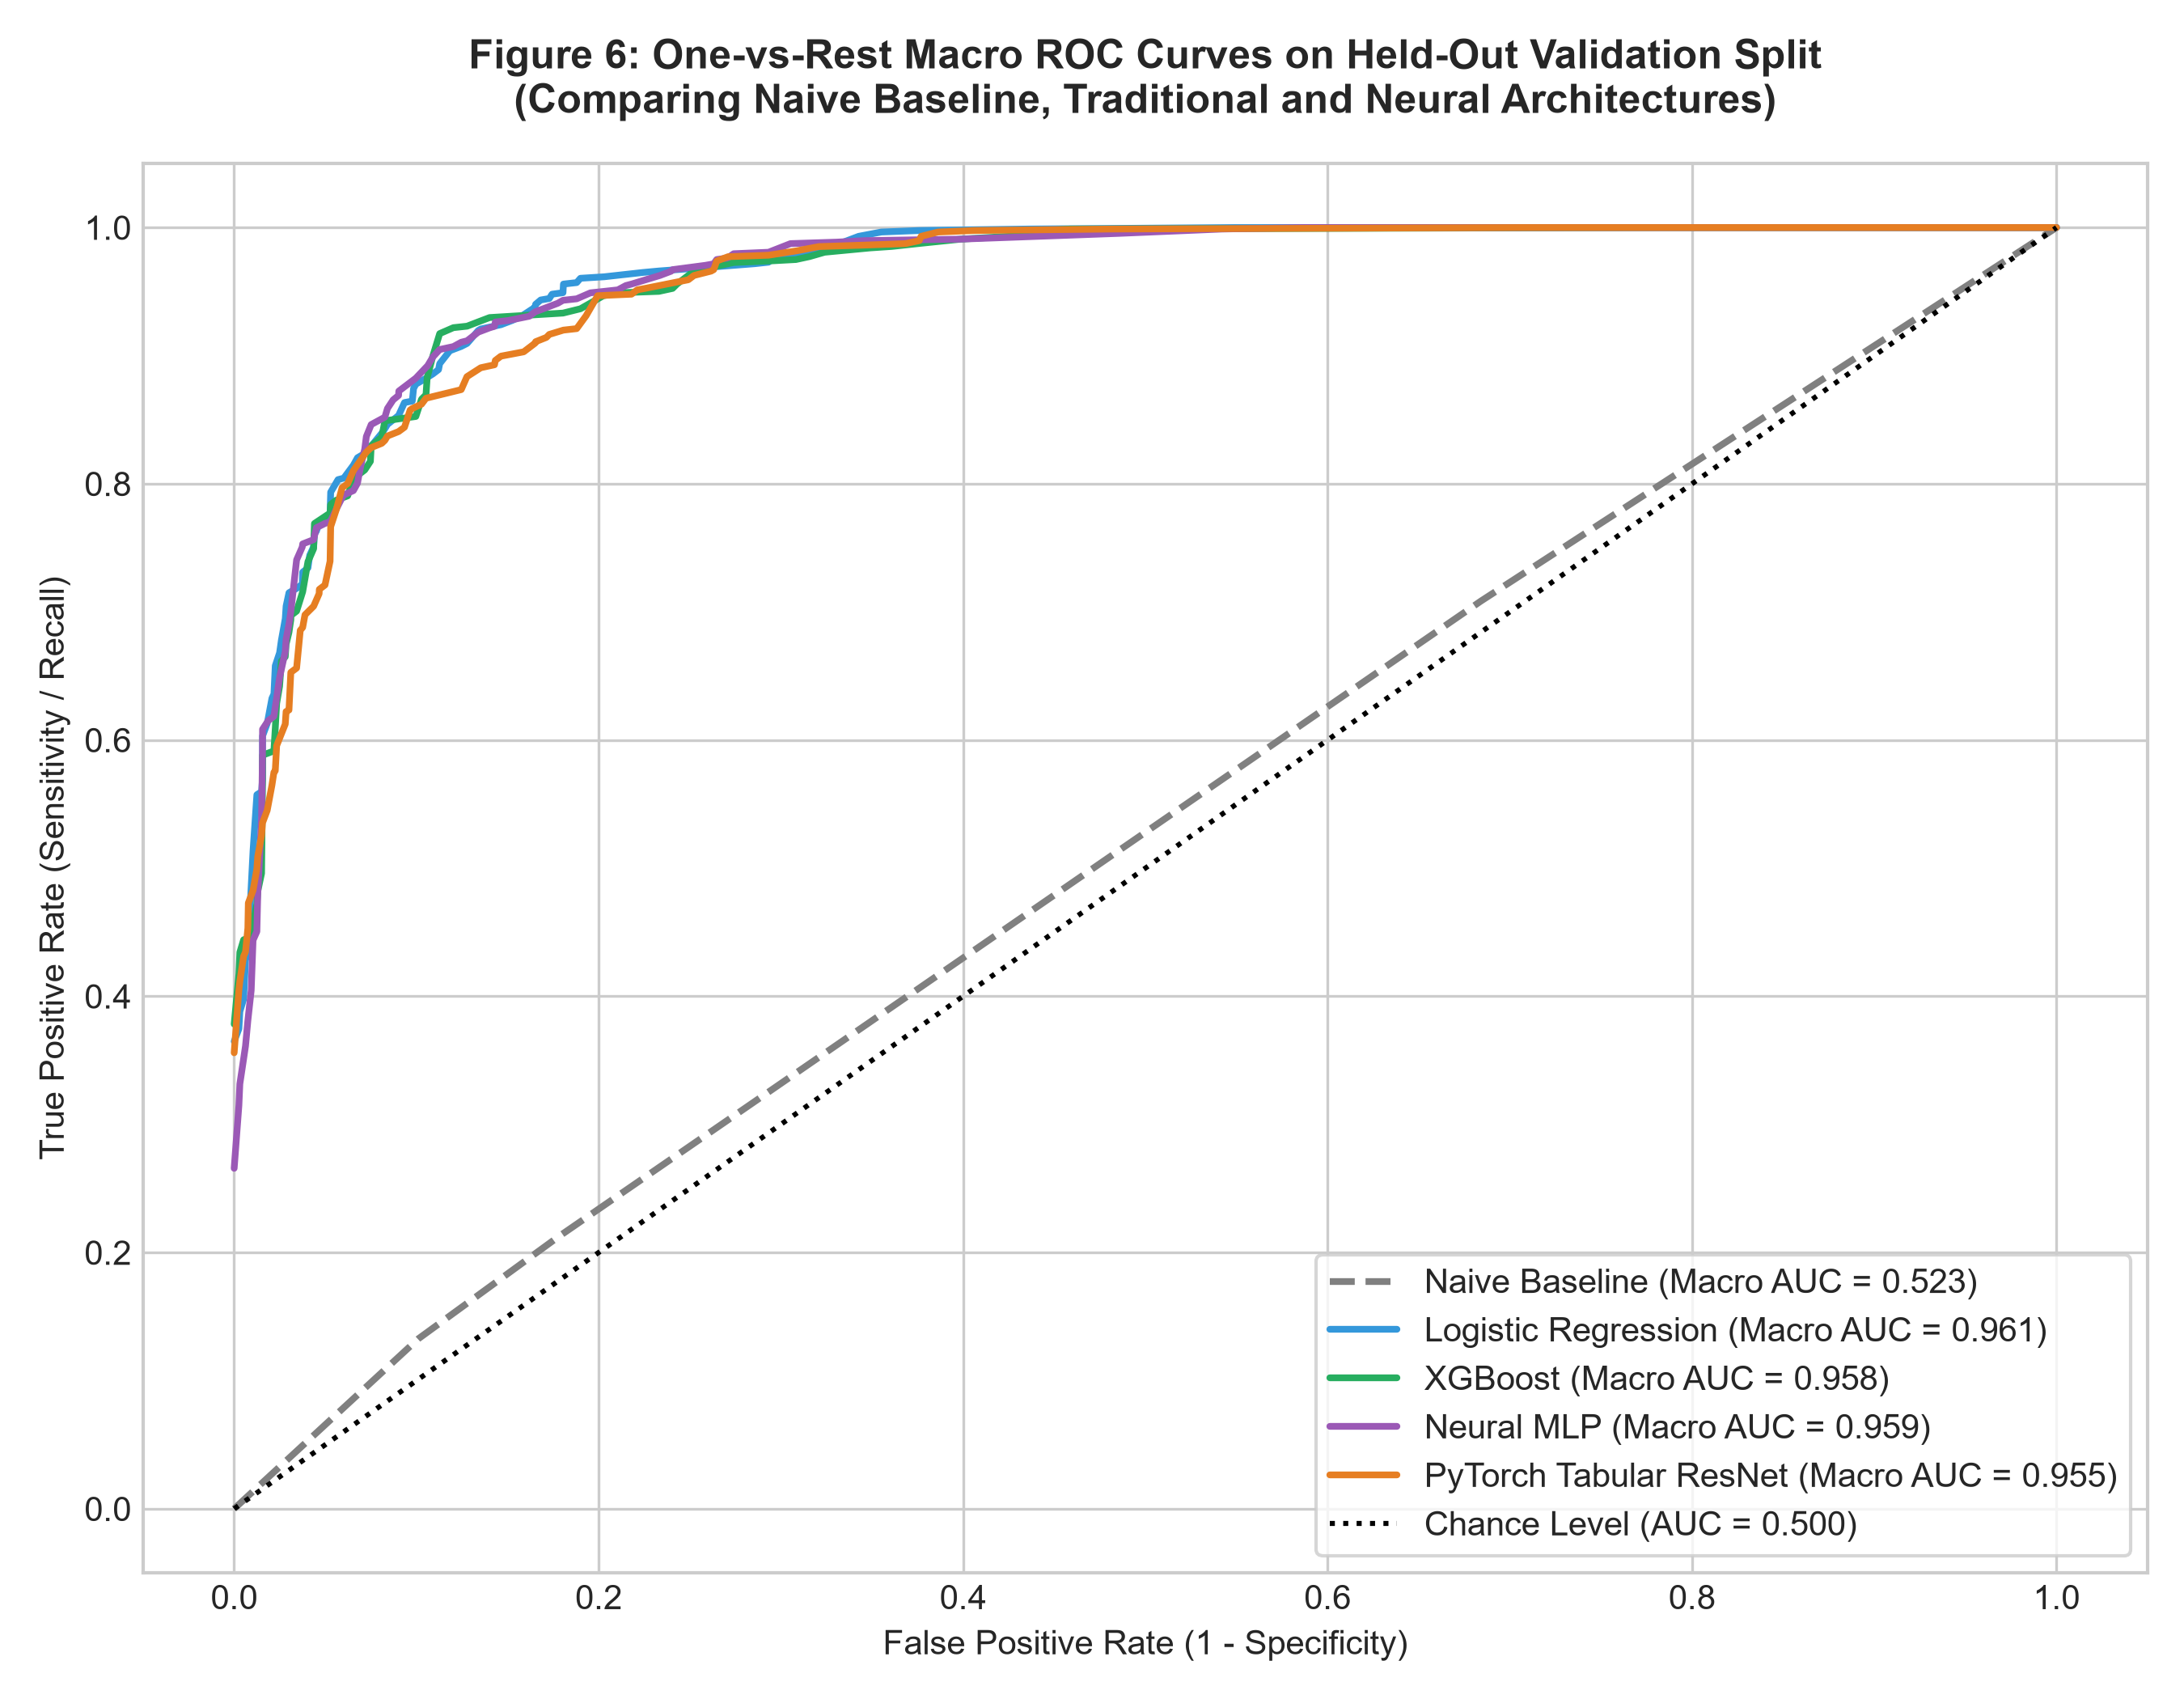

In [3]:
Image(filename=os.path.join(FIG_DIR, 'fig6_roc_curves.png'))


## 3. Overfitting & Generalisation Diagnostics (Figure 7)
Learning curves illustrating loss convergence and train vs validation Macro-F1 over epochs.


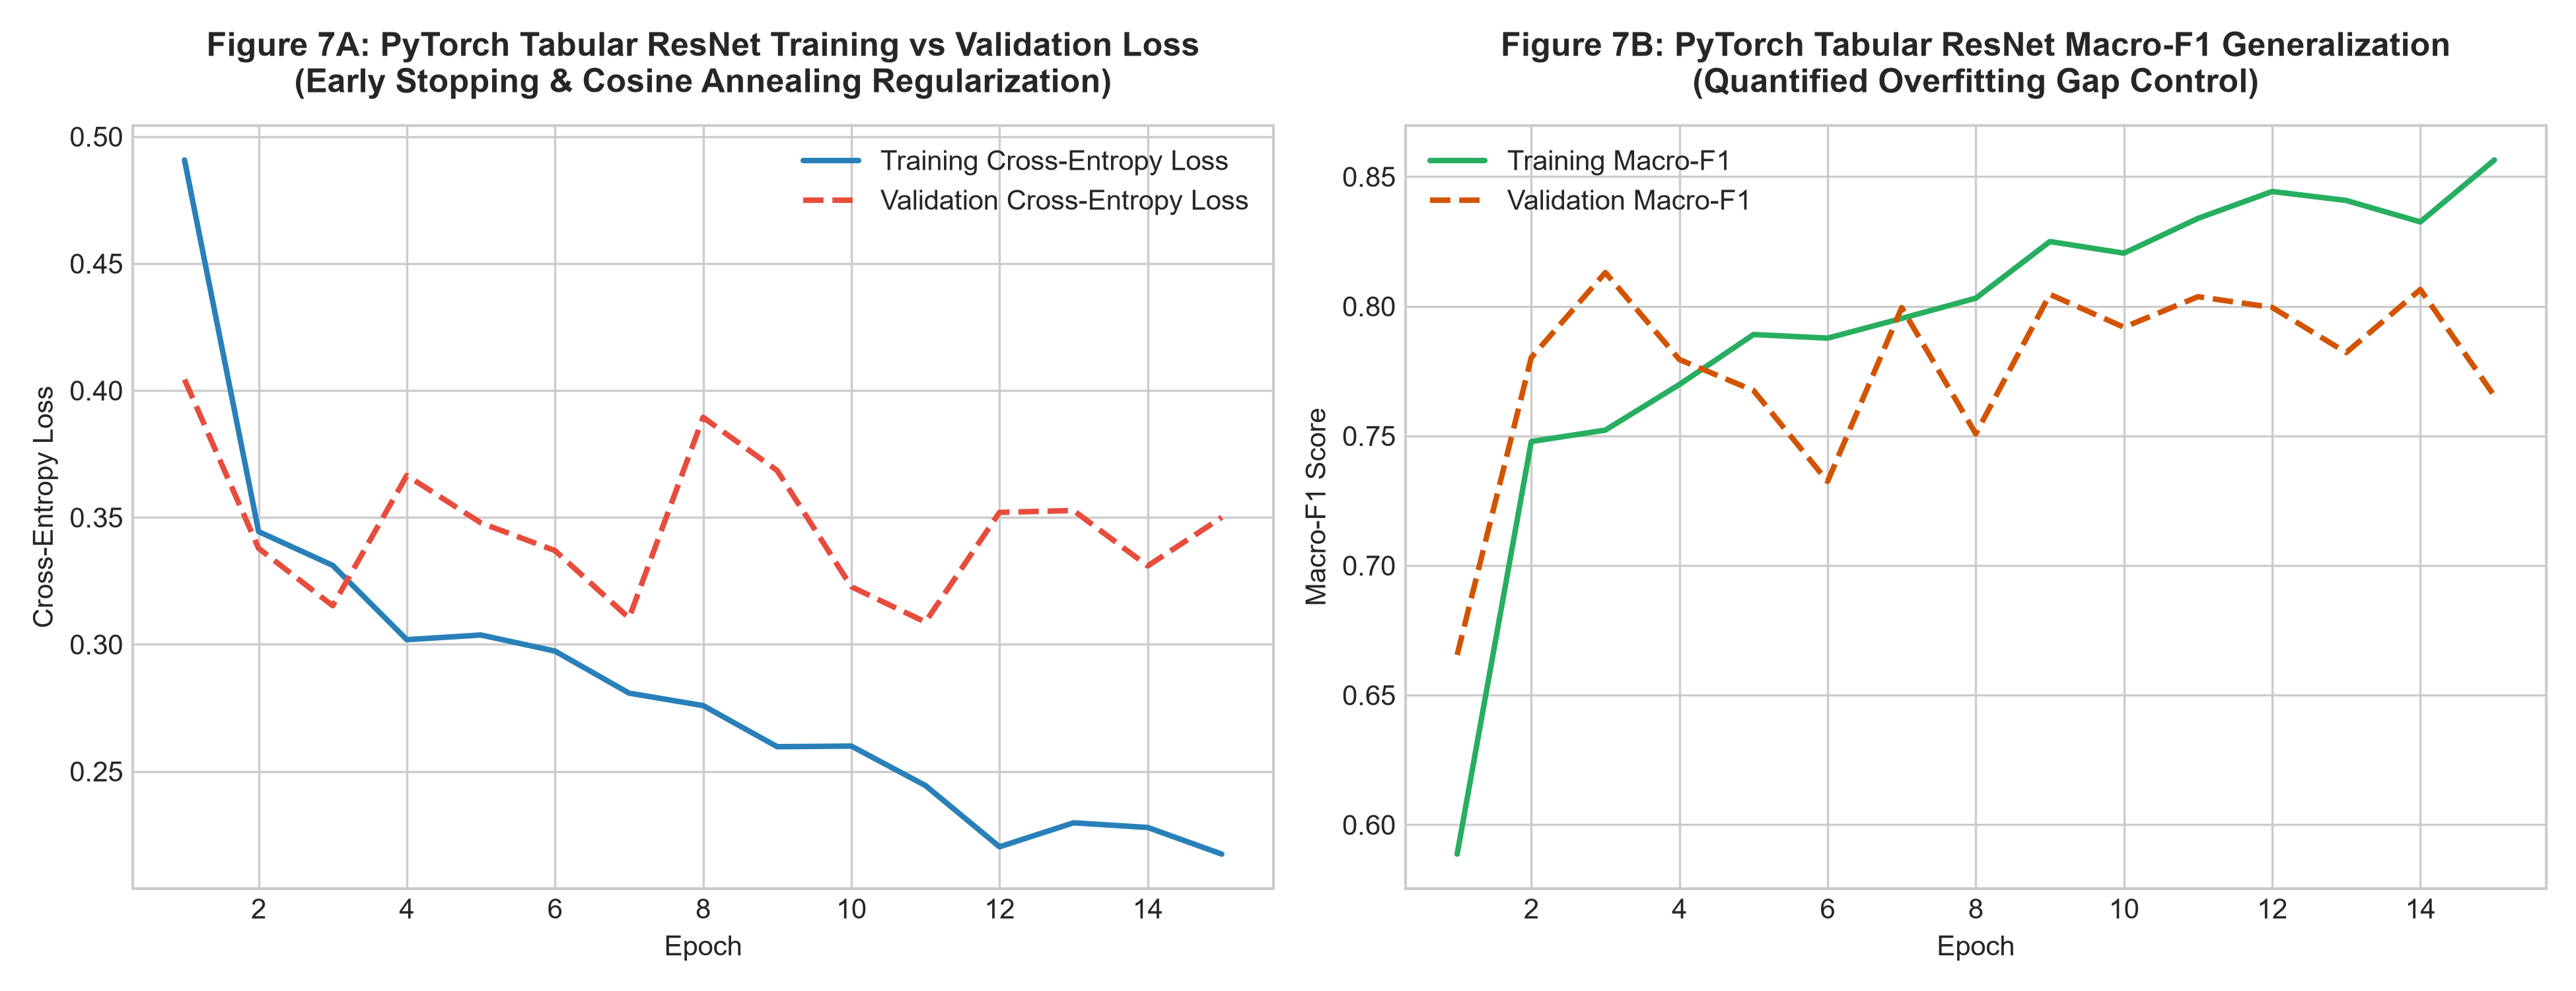

In [4]:
Image(filename=os.path.join(FIG_DIR, 'fig7_learning_curves.png'))


## 4. Multi-Class Confusion Matrices (Figure 9)
Normalized confusion matrices for all 5 models highlighting diagonal purity and minority class misclassifications.


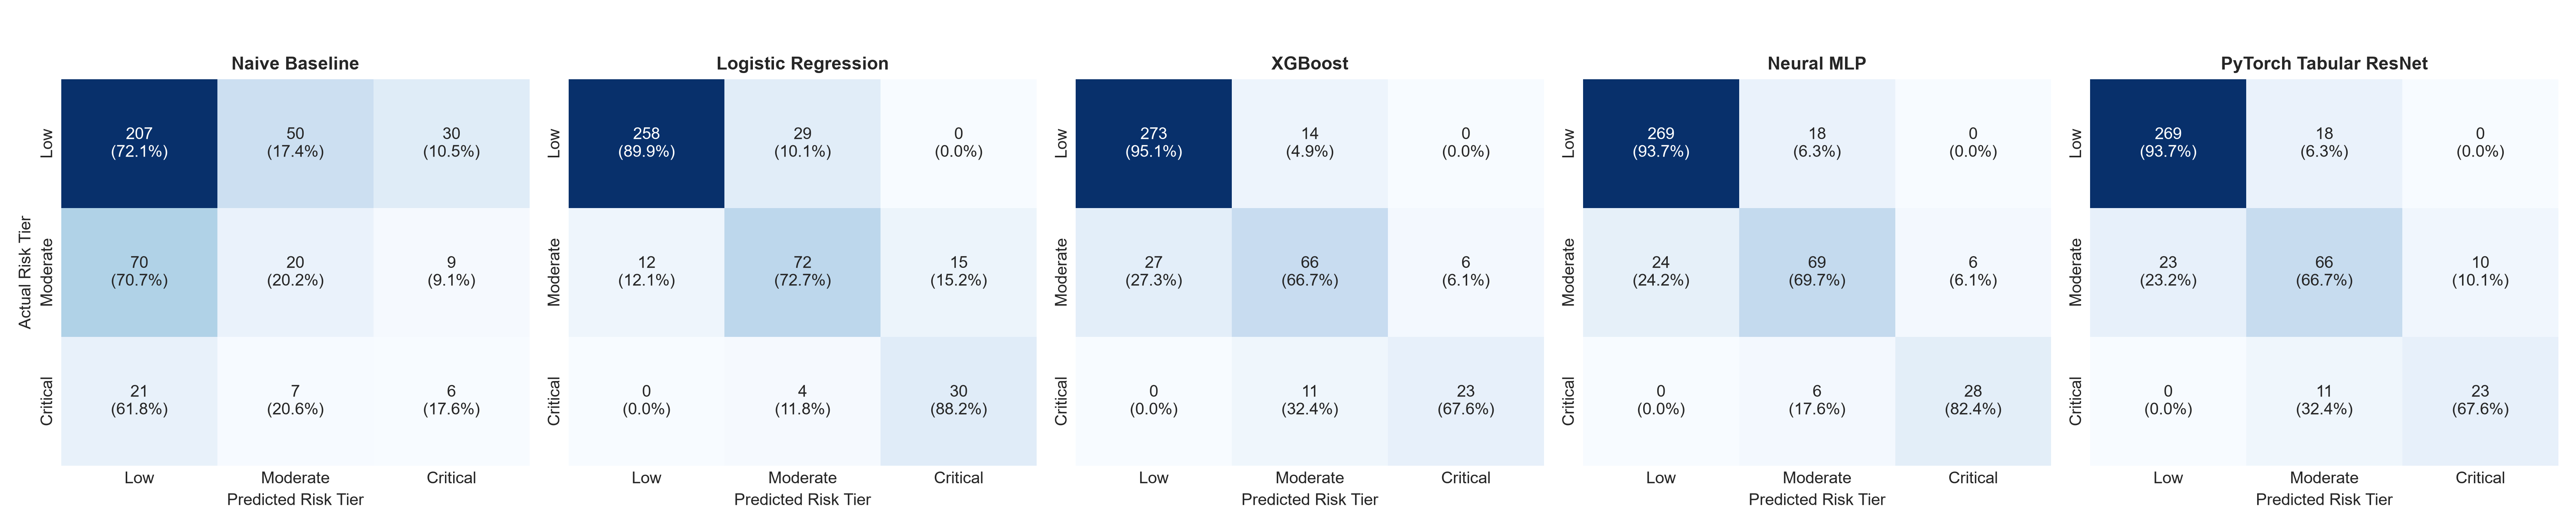

In [5]:
Image(filename=os.path.join(FIG_DIR, 'fig9_confusion_matrices.png'))


## 5. Detailed Classification Reports
Per-class precision, recall, and F1-score breakdown.


In [6]:
with open(os.path.join(REPORTS_DIR, 'classification_reports.md'), 'r') as f:
    report_content = f.read()
Markdown(report_content)


# Model Classification Reports on Held-Out Validation Split

## Naive Baseline
```text
                            precision    recall  f1-score   support

              Low Risk (0)       0.69      0.72      0.71       287
Moderate Vulnerability (1)       0.26      0.20      0.23        99
    Critical Emergency (2)       0.13      0.18      0.15        34

                  accuracy                           0.55       420
                 macro avg       0.36      0.37      0.36       420
              weighted avg       0.55      0.55      0.55       420

```

## Logistic Regression
```text
                            precision    recall  f1-score   support

              Low Risk (0)       0.96      0.90      0.93       287
Moderate Vulnerability (1)       0.69      0.73      0.71        99
    Critical Emergency (2)       0.67      0.88      0.76        34

                  accuracy                           0.86       420
                 macro avg       0.77      0.84      0.80       420
              weighted avg       0.87      0.86      0.86       420

```

## XGBoost
```text
                            precision    recall  f1-score   support

              Low Risk (0)       0.91      0.95      0.93       287
Moderate Vulnerability (1)       0.73      0.67      0.69        99
    Critical Emergency (2)       0.79      0.68      0.73        34

                  accuracy                           0.86       420
                 macro avg       0.81      0.76      0.79       420
              weighted avg       0.86      0.86      0.86       420

```

## Neural MLP
```text
                            precision    recall  f1-score   support

              Low Risk (0)       0.92      0.94      0.93       287
Moderate Vulnerability (1)       0.74      0.70      0.72        99
    Critical Emergency (2)       0.82      0.82      0.82        34

                  accuracy                           0.87       420
                 macro avg       0.83      0.82      0.82       420
              weighted avg       0.87      0.87      0.87       420

```

## PyTorch Tabular ResNet
```text
                            precision    recall  f1-score   support

              Low Risk (0)       0.92      0.94      0.93       287
Moderate Vulnerability (1)       0.69      0.67      0.68        99
    Critical Emergency (2)       0.70      0.68      0.69        34

                  accuracy                           0.85       420
                 macro avg       0.77      0.76      0.77       420
              weighted avg       0.85      0.85      0.85       420

```

